# Fairness–Performance Trade-offs of Bias Mitigation in ML Decision Software

**Study:** How well do pre-, in- and post-processing bias mitigation methods improve fairness, what do they cost in predictive performance, and can a cheap *data* fairness check before training predict *model* bias after training?

**Datasets** (all load automatically from OpenML through the `fairlearn` library; no login, no manual download):

| Task | Dataset | Protected attribute | Privileged group |
|---|---|---|---|
| adult-sex | UCI Adult (OpenML 1590) | sex | Male |
| adult-race | UCI Adult (OpenML 1590) | race | White |
| credit-sex | Default of Credit Card Clients (OpenML 42477) | SEX | male (code 1) |
| bank-age | Bank Marketing (OpenML 1461) | age | age ≥ 25 |
| diabetes-race | Diabetes 130-Hospitals, Fairlearn version (OpenML 43874) | race | Caucasian |

**Models:** Logistic Regression, Random Forest, Histogram Gradient Boosting.
**Mitigation:** none (baseline) · CorrelationRemover (pre) · ExponentiatedGradient with Demographic Parity (in) · ThresholdOptimizer with Equalized Odds (post).

### How to run
1. **Runtime → Change runtime type → CPU is fine** (no GPU needed). Save.
2. Leave `PILOT = True` in Step 2 and choose **Runtime → Run all** (about 10–15 minutes). Allow Google Drive access.
3. Check the pilot output, set `PILOT = False`, and **Run all** again (about 2–3 hours).
4. If Colab disconnects, reconnect and **Run all**: finished runs are read from Drive and skipped.

## Step 1 — Install libraries

In [6]:
!pip -q install -U fairlearn

## Step 2 — Settings and Google Drive
Edit settings in this cell only.

In [7]:
import os, time, json, platform, warnings
import numpy as np, pandas as pd
warnings.filterwarnings('ignore')

PILOT = True          # True = quick test; False = full study
SYNTHETIC_TEST = False  # leave False (only used to self-test the code without internet)

TASKS = ['adult-sex', 'adult-race', 'credit-sex', 'bank-age', 'diabetes-race']
MODELS = ['LR', 'RF', 'HGB']
METHODS = ['baseline', 'pre_CorrelationRemover', 'in_ExpGrad_DP', 'post_ThresholdOpt_EO']
SKEW_FACTORS = [0.5, 0.75, 1.0, 1.25, 1.5]   # RQ3: scale the unprivileged group's positive rate
TEST_SIZE = 0.3

if PILOT:
    SEEDS, MAX_ROWS, RQ3_SEEDS, RUN_TAG = [0], 8000, [0], 'pilot'
else:
    SEEDS, MAX_ROWS, RQ3_SEEDS, RUN_TAG = [0, 1, 2, 3, 4], 30000, [0, 1, 2], 'full'

try:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/fairness_study'
except ImportError:
    OUT_DIR = os.path.abspath('fairness_study')
os.makedirs(OUT_DIR, exist_ok=True)
RESULTS_CSV = os.path.join(OUT_DIR, f'results_{RUN_TAG}.csv')
RQ3_CSV = os.path.join(OUT_DIR, f'rq3_{RUN_TAG}.csv')
print('Mode:', RUN_TAG, '| seeds:', SEEDS, '| max rows per dataset:', MAX_ROWS)
print('Results:', RESULTS_CSV)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Mode: pilot | seeds: [0] | max rows per dataset: 8000
Results: /content/drive/MyDrive/fairness_study/results_pilot.csv


## Step 3 — Load the datasets and define the protected attributes
Each dataset is downloaded from OpenML on first use (a few seconds; Diabetes about 20 MB).
The positive class is the **minority outcome** in every dataset (e.g. income >50K, default, subscription, 30-day readmission);
the fairness metrics used are absolute differences, so they do not depend on which outcome is called "favourable".

In [8]:
from fairlearn.datasets import fetch_adult, fetch_credit_card, fetch_bank_marketing, fetch_diabetes_hospital

def _minority_binary(y):
    y = pd.Series(np.asarray(y)).astype(str).str.strip()
    counts = y.value_counts()
    assert len(counts) == 2, f'expected a binary target, got {list(counts.index)[:5]}'
    return (y == counts.index[-1]).astype(int).to_numpy()   # minority class -> 1

def _col(X, *names):
    for n in names:
        if n in X.columns:
            return n
    raise KeyError(f'None of {names} found. Columns are: {list(X.columns)}')

def _synthetic(name, seed=0, n=6000):
    rng = np.random.default_rng(abs(hash(name)) % 2**32)
    g = rng.random(n) < 0.6
    X = pd.DataFrame({'f1': rng.normal(size=n) + 0.6 * g, 'f2': rng.normal(size=n),
                      'cat': rng.choice(['a', 'b', 'c'], n), 'grp': np.where(g, 'P', 'U'),
                      'age': rng.integers(18, 70, n)})
    logit = 0.9 * X['f1'] - 0.5 * X['f2'] + 0.8 * g - 1.0
    y = (rng.random(n) < 1 / (1 + np.exp(-logit))).astype(int)
    return X, np.asarray(y).astype(int), 'grp', (X['grp'] == 'P').astype(int).to_numpy()

def load_task(task):
    """Return X (features incl. protected column), y (0/1), protected column name, privileged indicator (0/1)."""
    if SYNTHETIC_TEST:
        return _synthetic(task)
    if task.startswith('adult'):
        X, y = fetch_adult(return_X_y=True)
        c = _col(X, 'sex') if task == 'adult-sex' else _col(X, 'race')
        priv = (X[c].astype(str).str.strip() == ('Male' if task == 'adult-sex' else 'White')).astype(int)
    elif task == 'credit-sex':
        X, y = fetch_credit_card(return_X_y=True)
        c = _col(X, 'SEX', 'x2')
        priv = (pd.to_numeric(X[c], errors='coerce') == 1).astype(int)
    elif task == 'bank-age':
        X, y = fetch_bank_marketing(return_X_y=True)
        c = _col(X, 'age', 'V1')
        priv = (pd.to_numeric(X[c], errors='coerce') >= 25).astype(int)
    elif task == 'diabetes-race':
        X, y = fetch_diabetes_hospital(return_X_y=True)
        X = X.drop(columns=[k for k in X.columns if str(k).lower().startswith('readmit')])  # avoid target leakage
        c = _col(X, 'race')
        priv = (X[c].astype(str).str.strip() == 'Caucasian').astype(int)
    else:
        raise ValueError(task)
    return X.reset_index(drop=True), _minority_binary(y), c, priv.to_numpy()

DATA = {}
for t in TASKS:
    X, y, pcol, priv = load_task(t)
    if len(X) > MAX_ROWS:   # stratified subsample by (label, group) to bound run time
        strata = pd.Series(y).astype(str) + '_' + pd.Series(priv).astype(str)
        idx = (pd.DataFrame({'s': strata}).groupby('s', group_keys=False)
               .apply(lambda d: d.sample(frac=MAX_ROWS / len(X), random_state=42)).index.to_numpy())
        X, y, priv = X.iloc[idx].reset_index(drop=True), y[idx], priv[idx]
    DATA[t] = (X, y, pcol, priv)
    print(f'{t:14s} rows={len(X):6d} features={X.shape[1]:3d} positive rate={y.mean():.3f} '
          f'privileged share={priv.mean():.3f} | base-rate gap={abs(y[priv==1].mean()-y[priv==0].mean()):.3f}')

adult-sex      rows=  8000 features= 14 positive rate=0.239 privileged share=0.668 | base-rate gap=0.195
adult-race     rows=  8000 features= 14 positive rate=0.239 privileged share=0.855 | base-rate gap=0.101
credit-sex     rows=  7999 features= 23 positive rate=0.221 privileged share=0.396 | base-rate gap=0.034
bank-age       rows=  8001 features= 16 positive rate=0.117 privileged share=0.982 | base-rate gap=0.143
diabetes-race  rows=  7999 features= 22 positive rate=0.112 privileged share=0.748 | base-rate gap=0.005


## Step 4 — Pre-processing, models, mitigation methods and metrics

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from fairlearn.preprocessing import CorrelationRemover
from fairlearn.reductions import ExponentiatedGradient, DemographicParity
from fairlearn.postprocessing import ThresholdOptimizer
from fairlearn.metrics import demographic_parity_difference, equalized_odds_difference

PROT = '__protected__'

def encode(X, pcol, priv):
    """One-hot encode features; replace the raw protected column by a single 0/1 column."""
    Xe = X.drop(columns=[pcol]).copy()
    for c in Xe.columns:
        if not pd.api.types.is_numeric_dtype(Xe[c]):
            Xe[c] = Xe[c].astype(str)
    Xe = pd.get_dummies(Xe, dummy_na=False).astype(float)
    Xe = Xe.fillna(Xe.median(numeric_only=True)).fillna(0.0)
    Xe[PROT] = priv.astype(float)
    Xe.columns = [str(c) for c in Xe.columns]
    return Xe

def make_model(name, seed):
    if name == 'LR':
        return LogisticRegression(max_iter=2000)
    if name == 'RF':
        return RandomForestClassifier(n_estimators=50, max_depth=12, min_samples_leaf=5, n_jobs=-1, random_state=seed)
    if name == 'HGB':
        return HistGradientBoostingClassifier(max_iter=100, random_state=seed)
    raise ValueError(name)

def split_scale(Xe, y, priv, seed):
    y, priv = np.asarray(y).astype(int), np.asarray(priv).astype(int)
    strat = pd.Series(y).astype(str) + '_' + pd.Series(priv).astype(str)
    Xtr, Xte, ytr, yte, ptr, pte = train_test_split(Xe, y, priv, test_size=TEST_SIZE, random_state=seed, stratify=strat)
    num = [c for c in Xtr.columns if c != PROT and Xtr[c].nunique() > 2]
    sc = StandardScaler().fit(Xtr[num]) if num else None
    Xtr, Xte = Xtr.copy(), Xte.copy()
    if sc is not None:
        Xtr[num] = sc.transform(Xtr[num]); Xte[num] = sc.transform(Xte[num])
    return Xtr, Xte, ytr, yte, ptr, pte

def fit_predict(method, model_name, Xtr, ytr, ptr, Xte, pte, seed):
    est = make_model(model_name, seed)
    if method == 'baseline':
        est.fit(Xtr, ytr); return est.predict(Xte)
    if method == 'pre_CorrelationRemover':
        cr = CorrelationRemover(sensitive_feature_ids=[PROT], alpha=1.0).fit(Xtr)
        est.fit(cr.transform(Xtr), ytr); return est.predict(cr.transform(Xte))
    if method == 'in_ExpGrad_DP':
        eg = ExponentiatedGradient(est, constraints=DemographicParity(), max_iter=50)
        eg.fit(Xtr, ytr, sensitive_features=ptr)
        return eg.predict(Xte, random_state=seed)
    if method == 'post_ThresholdOpt_EO':
        to = ThresholdOptimizer(estimator=est, constraints='equalized_odds', predict_method='auto', prefit=False)
        to.fit(Xtr, ytr, sensitive_features=ptr)
        return to.predict(Xte, sensitive_features=pte, random_state=seed)
    raise ValueError(method)

def evaluate(yte, yhat, pte):
    yhat = np.asarray(yhat).astype(int)
    sel = lambda g: float(yhat[pte == g].mean()) if (pte == g).any() else np.nan
    return {'accuracy': accuracy_score(yte, yhat), 'balanced_accuracy': balanced_accuracy_score(yte, yhat),
            'f1': f1_score(yte, yhat, zero_division=0),
            'dpd': demographic_parity_difference(yte, yhat, sensitive_features=pte),
            'eod': equalized_odds_difference(yte, yhat, sensitive_features=pte),
            'sel_rate_priv': sel(1), 'sel_rate_unpriv': sel(0)}

ENC = {t: encode(*[DATA[t][i] for i in (0, 2, 3)]) for t in TASKS}
for t in TASKS:
    print(t, ENC[t].shape)

adult-sex (8000, 106)
adult-race (8000, 101)
credit-sex (7999, 23)
bank-age (8001, 51)
diabetes-race (7999, 53)


## Step 5 — RQ1/RQ2: run all task × model × method × seed combinations (resumable)

In [5]:
def done(path):
    return set(pd.read_csv(path)['key']) if os.path.exists(path) else set()

def append(path, row):
    pd.DataFrame([row]).to_csv(path, mode='a', index=False, header=not os.path.exists(path))

keys = [(t, m, me, s) for t in TASKS for m in MODELS for me in METHODS for s in SEEDS]
finished = done(RESULTS_CSV); start = time.time(); n_new = 0
for t, m, me, s in keys:
    key = f'{t}|{m}|{me}|s{s}'
    if key in finished:
        continue
    X, y, pcol, priv = DATA[t]
    Xtr, Xte, ytr, yte, ptr, pte = split_scale(ENC[t], y, priv, s)
    t0 = time.time()
    try:
        yhat = fit_predict(me, m, Xtr, ytr, ptr, Xte, pte, s)
    except Exception as e:
        print('  FAILED', key, repr(e)[:150]); continue
    row = {'key': key, 'task': t, 'model': m, 'method': me, 'seed': s,
           'n_train': len(ytr), 'n_test': len(yte), 'fit_seconds': time.time() - t0, **evaluate(yte, yhat, pte)}
    append(RESULTS_CSV, row); n_new += 1
    print(f"{key:48s} acc={row['accuracy']:.3f} f1={row['f1']:.3f} dpd={row['dpd']:.3f} eod={row['eod']:.3f} "
          f"({row['fit_seconds']:.1f}s) | {len(done(RESULTS_CSV))}/{len(keys)} | {(time.time()-start)/60:.1f} min")
print('Done. New runs:', n_new, '| total:', len(done(RESULTS_CSV)), 'of', len(keys))

adult-sex|LR|baseline|s0                         acc=0.845 f1=0.652 dpd=0.217 eod=0.190 (1.0s) | 1/60 | 0.0 min
adult-sex|LR|pre_CorrelationRemover|s0           acc=0.843 f1=0.640 dpd=0.124 eod=0.036 (0.8s) | 2/60 | 0.1 min
adult-sex|LR|in_ExpGrad_DP|s0                    acc=0.832 f1=0.597 dpd=0.041 eod=0.214 (10.3s) | 3/60 | 0.2 min
adult-sex|LR|post_ThresholdOpt_EO|s0             acc=0.827 f1=0.585 dpd=0.103 eod=0.100 (1.5s) | 4/60 | 0.3 min
adult-sex|RF|baseline|s0                         acc=0.853 f1=0.636 dpd=0.186 eod=0.228 (0.5s) | 5/60 | 0.3 min
adult-sex|RF|pre_CorrelationRemover|s0           acc=0.845 f1=0.620 dpd=0.174 eod=0.191 (0.6s) | 6/60 | 0.3 min
adult-sex|RF|in_ExpGrad_DP|s0                    acc=0.830 f1=0.553 dpd=0.022 eod=0.228 (7.3s) | 7/60 | 0.4 min
adult-sex|RF|post_ThresholdOpt_EO|s0             acc=0.833 f1=0.561 dpd=0.114 eod=0.173 (0.4s) | 8/60 | 0.4 min
adult-sex|HGB|baseline|s0                        acc=0.863 f1=0.701 dpd=0.214 eod=0.239 (1.1s) | 9/60 |

## Step 6 — RQ3: does data (label) bias before training predict model bias after training?
For each task we resample the training set so that the unprivileged group's positive rate is scaled by each factor
in `SKEW_FACTORS`, measure the **data bias** (absolute gap in positive-label rate between groups in the training
data), train each baseline model, and measure **model bias** (demographic parity difference on the untouched test set).

In [10]:
def skew_train(Xtr, ytr, ptr, factor, seed):
    """Resample the unprivileged group so its positive-label rate becomes factor x original (capped to [0.02, 0.98])."""
    rng = np.random.default_rng(seed)
    ytr, ptr = np.asarray(ytr), np.asarray(ptr)
    u = np.where(ptr == 0)[0]; pos = u[ytr[u] == 1]; neg = u[ytr[u] == 0]
    r0 = len(pos) / max(len(u), 1); r1 = float(np.clip(r0 * factor, 0.02, 0.98))
    n = len(u)
    keep_pos = rng.choice(pos, int(round(r1 * n)), replace=int(round(r1 * n)) > len(pos))
    keep_neg = rng.choice(neg, n - len(keep_pos), replace=(n - len(keep_pos)) > len(neg))
    idx = np.concatenate([np.where(ptr == 1)[0], keep_pos, keep_neg])
    return Xtr.iloc[idx], ytr[idx], ptr[idx]

rq3_done = done(RQ3_CSV)
for t in TASKS:
    X, y, pcol, priv = DATA[t]
    for s in RQ3_SEEDS:
        Xtr, Xte, ytr, yte, ptr, pte = split_scale(ENC[t], y, priv, s)
        for f in SKEW_FACTORS:
            Xs, ys, ps = skew_train(Xtr, ytr, ptr, f, s)
            data_gap = abs(ys[ps == 1].mean() - ys[ps == 0].mean())
            for m in MODELS:
                key = f'{t}|{m}|skew{f}|s{s}'
                if key in rq3_done:
                    continue
                est = make_model(m, s).fit(Xs, ys)
                ev = evaluate(yte, est.predict(Xte), pte)
                append(RQ3_CSV, {'key': key, 'task': t, 'model': m, 'skew': f, 'seed': s,
                                 'data_label_gap': data_gap, 'model_dpd': ev['dpd'], 'model_eod': ev['eod'],
                                 'accuracy': ev['accuracy']})
    print('RQ3 done for', t)

RQ3 done for adult-sex
RQ3 done for adult-race
RQ3 done for credit-sex
RQ3 done for bank-age
RQ3 done for diabetes-race


## Step 7 — Analysis tables (saved to Drive)
- **Table A:** baseline performance and fairness per task (mean ± std over seeds and models)
- **Table B:** mean change versus baseline per mitigation method (Δaccuracy, ΔF1, ΔDPD, ΔEOD)
- **Table C:** outcome categories per method (fairness improved / unchanged / worsened × accuracy)
- **Table D:** RQ3 Spearman correlation between data bias and model bias

In [11]:
from scipy.stats import mannwhitneyu, spearmanr
df = pd.read_csv(RESULTS_CSV)
ALPHA = 0.05

# Table A
tabA = (df[df.method == 'baseline'].groupby('task')[['accuracy', 'f1', 'dpd', 'eod']]
        .agg(['mean', 'std']).round(3))

# Per-scenario comparison against the baseline (scenario = task x model)
def effect(base, treat, lower_is_better):
    if len(base) < 2 or len(treat) < 2 or np.allclose(base.std(), 0) and np.allclose(treat.std(), 0) and np.isclose(base.mean(), treat.mean()):
        p = 1.0
    else:
        p = mannwhitneyu(base, treat, alternative='two-sided').pvalue
    d = treat.mean() - base.mean()
    if p >= ALPHA:
        return 'unchanged', d, p
    better = d < 0 if lower_is_better else d > 0
    return ('improved' if better else 'worsened'), d, p

rows = []
for (t, m), g in df.groupby(['task', 'model']):
    b = g[g.method == 'baseline']
    for me in METHODS[1:]:
        tr = g[g.method == me]
        if b.empty or tr.empty:
            continue
        r = {'task': t, 'model': m, 'method': me}
        for metric, lib in [('accuracy', False), ('f1', False), ('dpd', True), ('eod', True)]:
            cat, d, p = effect(b[metric].to_numpy(), tr[metric].to_numpy(), lib)
            r[f'd_{metric}'] = d; r[f'{metric}_effect'] = cat; r[f'p_{metric}'] = p
        rows.append(r)
cmp_df = pd.DataFrame(rows)

# Table B
tabB = cmp_df.groupby('method')[['d_accuracy', 'd_f1', 'd_dpd', 'd_eod']].agg(['mean', 'std']).round(3)

# Table C: fairness (DPD) effect x accuracy effect, counted over scenarios
def outcome(r, fair='dpd'):
    f, a = r[f'{fair}_effect'], r['accuracy_effect']
    if f == 'improved' and a != 'worsened': return 'win-win / free'
    if f == 'improved' and a == 'worsened': return 'trade-off'
    if f == 'unchanged':                     return 'no fairness gain'
    return 'lose (fairness worse)'
cmp_df['outcome_dpd'] = cmp_df.apply(outcome, axis=1)
cmp_df['outcome_eod'] = cmp_df.apply(lambda r: outcome(r, 'eod'), axis=1)
tabC = pd.concat({'by DPD': cmp_df.pivot_table(index='method', columns='outcome_dpd', values='task', aggfunc='count', fill_value=0),
                  'by EOD': cmp_df.pivot_table(index='method', columns='outcome_eod', values='task', aggfunc='count', fill_value=0)}, axis=1)

# Best method per scenario (largest DPD reduction among methods that do not significantly lower accuracy)
ok = cmp_df[cmp_df.accuracy_effect != 'worsened']
best = (ok.loc[ok.groupby(['task', 'model'])['d_dpd'].idxmin()][['task', 'model', 'method', 'd_dpd', 'd_accuracy']]
        if not ok.empty else pd.DataFrame())

# Table D (RQ3)
rq = pd.read_csv(RQ3_CSV)
rq3_rows = []
for t, g in list(rq.groupby('task')) + [('ALL', rq)]:
    rho, p = spearmanr(g['data_label_gap'], g['model_dpd'])
    rq3_rows.append({'task': t, 'n': len(g), 'spearman_rho': round(rho, 3), 'p_value': p})
tabD = pd.DataFrame(rq3_rows)

for name, tab in [('tableA_baseline', tabA), ('tableB_deltas', tabB), ('tableC_outcomes', tabC),
                  ('tableD_rq3', tabD), ('best_method_per_scenario', best), ('comparisons', cmp_df)]:
    tab.to_csv(os.path.join(OUT_DIR, f'{name}_{RUN_TAG}.csv'))
pd.set_option('display.width', 220)
if len(SEEDS) < 3:
    print('NOTE: pilot mode uses one seed, so the significance tests cannot run and Table C shows "no fairness gain"\n'
          'for every scenario. This is expected; the full run (5 seeds) gives real categories.\n')
print('TABLE A — baseline\n', tabA, '\n\nTABLE B — mean change vs baseline\n', tabB,
      '\n\nTABLE C — outcome counts (scenarios)\n', tabC, '\n\nTABLE D — RQ3\n', tabD,
      '\n\nBest method per scenario\n', best)

NOTE: pilot mode uses one seed, so the significance tests cannot run and Table C shows "no fairness gain"
for every scenario. This is expected; the full run (5 seeds) gives real categories.

TABLE A — baseline
               accuracy            f1           dpd           eod       
                  mean    std   mean    std   mean    std   mean    std
task                                                                   
adult-race       0.865  0.009  0.694  0.024  0.094  0.008  0.081  0.040
adult-sex        0.853  0.009  0.663  0.034  0.206  0.017  0.219  0.026
bank-age         0.896  0.001  0.386  0.101  0.078  0.013  0.154  0.136
credit-sex       0.801  0.004  0.379  0.055  0.011  0.002  0.013  0.005
diabetes-race    0.888  0.001  0.000  0.000  0.001  0.002  0.001  0.002 

TABLE B — mean change vs baseline
                        d_accuracy          d_f1         d_dpd         d_eod       
                             mean    std   mean    std   mean    std   mean    std
method    

## Step 8 — Figures (300 dpi PNG and PDF, saved to Drive)

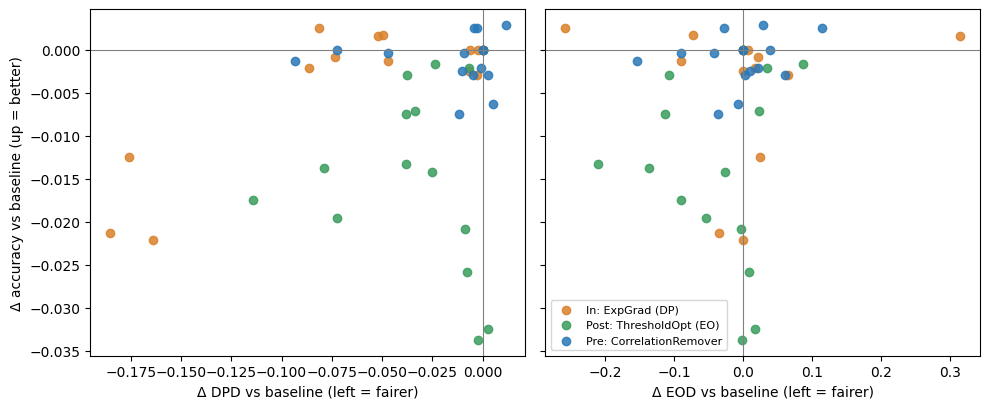

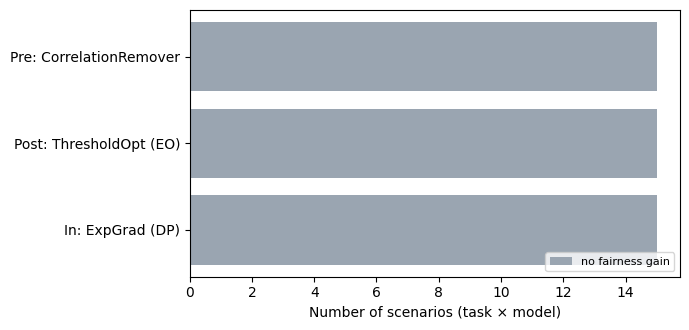

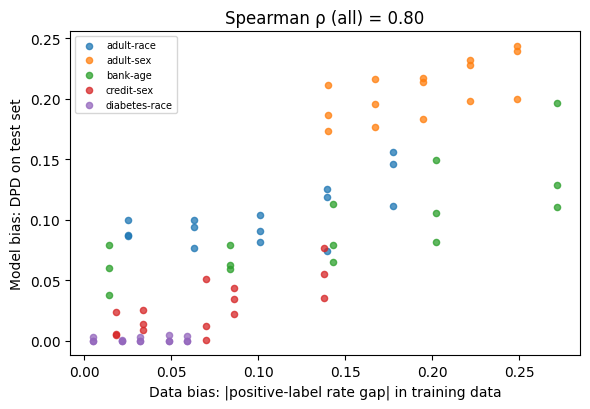

In [12]:
import matplotlib.pyplot as plt
FIG = os.path.join(OUT_DIR, f'figures_{RUN_TAG}'); os.makedirs(FIG, exist_ok=True)
COL = {'pre_CorrelationRemover': '#2a78b8', 'in_ExpGrad_DP': '#d9822b', 'post_ThresholdOpt_EO': '#3a9d5d'}
LBL = {'pre_CorrelationRemover': 'Pre: CorrelationRemover', 'in_ExpGrad_DP': 'In: ExpGrad (DP)',
       'post_ThresholdOpt_EO': 'Post: ThresholdOpt (EO)'}
def save(fig, name):
    fig.tight_layout()
    for ext in ('png', 'pdf'):
        fig.savefig(f'{FIG}/{name}.{ext}', dpi=300)
    plt.show()

# Fig 1: trade-off plane (one point per task x model)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for ax, fm in zip(axes, ['dpd', 'eod']):
    for me, g in cmp_df.groupby('method'):
        ax.scatter(g[f'd_{fm}'], g['d_accuracy'], s=36, alpha=.85, color=COL.get(me), label=LBL.get(me, me))
    ax.axhline(0, color='grey', lw=.8); ax.axvline(0, color='grey', lw=.8)
    ax.set_xlabel(f'Δ {fm.upper()} vs baseline (left = fairer)')
axes[0].set_ylabel('Δ accuracy vs baseline (up = better)'); axes[1].legend(fontsize=8, loc='lower left')
save(fig, 'fig1_tradeoff')

# Fig 2: outcome categories per method (DPD)
order = ['win-win / free', 'trade-off', 'no fairness gain', 'lose (fairness worse)']
pc = cmp_df.pivot_table(index='method', columns='outcome_dpd', values='task', aggfunc='count', fill_value=0)
pc = pc.reindex(columns=[c for c in order if c in pc.columns])
fig, ax = plt.subplots(figsize=(7, 3.4))
left = np.zeros(len(pc))
CAT_COL = {'win-win / free': '#3a9d5d', 'trade-off': '#e0b040', 'no fairness gain': '#9aa5b1', 'lose (fairness worse)': '#c4473a'}
for c in pc.columns:
    ax.barh([LBL.get(i, i) for i in pc.index], pc[c], left=left, color=CAT_COL[c], label=c); left += pc[c].to_numpy()
ax.set_xlabel('Number of scenarios (task × model)'); ax.legend(fontsize=8, ncol=2, loc='lower right')
save(fig, 'fig2_outcomes')

# Fig 3: RQ3 data bias vs model bias
fig, ax = plt.subplots(figsize=(6, 4.2))
for t, g in rq.groupby('task'):
    ax.scatter(g['data_label_gap'], g['model_dpd'], s=20, alpha=.75, label=t)
rho_all = tabD.loc[tabD.task == 'ALL', 'spearman_rho'].iloc[0]
ax.set_xlabel('Data bias: |positive-label rate gap| in training data'); ax.set_ylabel('Model bias: DPD on test set')
ax.set_title(f'Spearman ρ (all) = {rho_all:.2f}'); ax.legend(fontsize=7)
save(fig, 'fig3_rq3_data_vs_model')

## Step 9 — Record the environment (for the reproducibility section)

In [13]:
import sklearn, fairlearn, scipy
env = {'python': platform.python_version(), 'scikit-learn': sklearn.__version__, 'fairlearn': fairlearn.__version__,
       'pandas': pd.__version__, 'numpy': np.__version__, 'scipy': scipy.__version__,
       'cpu_count': os.cpu_count(), 'seeds': SEEDS, 'max_rows': MAX_ROWS, 'test_size': TEST_SIZE,
       'n_runs_rq12': len(pd.read_csv(RESULTS_CSV)), 'n_runs_rq3': len(pd.read_csv(RQ3_CSV)),
       'dataset_rows': {t: int(len(DATA[t][1])) for t in TASKS},
       'total_fit_hours': round(pd.read_csv(RESULTS_CSV)['fit_seconds'].sum() / 3600, 2)}
json.dump(env, open(os.path.join(OUT_DIR, f'environment_{RUN_TAG}.json'), 'w'), indent=2)
env

{'python': '3.13.16',
 'scikit-learn': '1.6.1',
 'fairlearn': '0.15.0',
 'pandas': '2.2.3',
 'numpy': '2.1.3',
 'scipy': '1.16.3',
 'cpu_count': 2,
 'seeds': [0],
 'max_rows': 8000,
 'test_size': 0.3,
 'n_runs_rq12': 60,
 'n_runs_rq3': 75,
 'dataset_rows': {'adult-sex': 8000,
  'adult-race': 8000,
  'credit-sex': 7999,
  'bank-age': 8001,
  'diabetes-race': 7999},
 'total_fit_hours': np.float64(0.07)}